# Oral Cavity Segmentation - Mobile-UNet: Hyperparameter Sweeps

**Fully standalone notebook** - loads the dataset, builds masks, trains the baseline
Mobile-UNet from scratch, then runs only the selected hyperparameter sweeps:

1. Data pipeline (Kaggle dataset -> COCO masks -> train/val tf.data pipeline)
2. Train the baseline Mobile-UNet
3. Hyperparameter sweeps: learning rate, batch size, dropout, weight decay, and epoch budget
4. One comparison table and chart for these sweep results

All experiments use the original seed (42). The normal sweeps run for 10 epochs each.

## 1. Environment Check

In [1]:
import sys, platform
import tensorflow as tf

print("Python:", sys.version)
print("Platform:", platform.platform())
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Platform: Linux-6.12.90+-x86_64-with-glibc2.35
TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Kaggle Input Check

In [2]:
import os
print("Available Kaggle input datasets:")
for d in os.listdir("/kaggle/input"):
    print(" -", d)


Available Kaggle input datasets:
 - datasets


## Imports

In [3]:
import os
import json
import random
import shutil
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, backend as K

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## Config & Output Folder

In [4]:
MODEL_NAME = "mobile_unet"

OUTPUT_DIR = Path("/kaggle/working/Segmentation Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MASKS_DIR = OUTPUT_DIR / "masks"
MASKS_DIR.mkdir(parents=True, exist_ok=True)

RESULT_DIR = OUTPUT_DIR / f"{MODEL_NAME}_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

SEGMENTED_DIR = RESULT_DIR / "segmented_samples"
SEGMENTED_DIR.mkdir(parents=True, exist_ok=True)

EXP_DIR = OUTPUT_DIR / "finetuning_experiments"
EXP_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 256
BATCH_SIZE = 8
BASELINE_EPOCHS = 50  # maximum; early stopping restores the best validation-Dice weights
BASELINE_EARLY_STOPPING_PATIENCE = 7
BASELINE_EARLY_STOPPING_MIN_DELTA = 0.001
HPARAM_SWEEP_EPOCHS = 10  # 10 epochs for LR, batch-size, dropout, and weight-decay sweeps
RESUME_EXISTING = True  # skip a variant if its best checkpoint + history already exist

RUN_LR_SWEEP = True
RUN_BATCH_SWEEP = True
RUN_DROPOUT_SWEEP = True
RUN_WEIGHT_DECAY_SWEEP = True
RUN_EPOCH_BUDGET_SWEEP = False  # disabled: Stage 1 = baseline + 12 hyperparameter variants = 13 models total

print("Output folder:", OUTPUT_DIR)
print("Baseline result folder:", RESULT_DIR)
print("Fine-tuning experiments folder:", EXP_DIR)


Output folder: /kaggle/working/Segmentation Output
Baseline result folder: /kaggle/working/Segmentation Output/mobile_unet_results
Fine-tuning experiments folder: /kaggle/working/Segmentation Output/finetuning_experiments


## 2. Dataset `Categories` Folder

In [5]:
DATASET_DIR = Path(
    "/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project"
)

print("Categories folder:", DATASET_DIR)
print("Exists:", DATASET_DIR.exists())


Categories folder: /kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project
Exists: True


## 3. COCO Annotation JSON

In [6]:
ANNOTATION_FILE = Path(
    "/kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json"
)

print("Annotation file:", ANNOTATION_FILE)
print("Exists:", ANNOTATION_FILE.exists())


Annotation file: /kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json
Exists: True


## 4. Load & Verify `Lesion` and `Oral Cavity` Categories

In [7]:
with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

print("Images:", len(coco["images"]))
print("Annotations:", len(coco["annotations"]))
print("Categories:", coco["categories"])

name_to_id = {c["name"]: c["id"] for c in coco["categories"]}
assert "Lesion" in name_to_id, "Lesion category not found"
assert "Oral Cavity" in name_to_id, "Oral Cavity category not found"

CATEGORY_ID_LESION = name_to_id["Lesion"]
CATEGORY_ID_ORAL = name_to_id["Oral Cavity"]

print("Lesion id:", CATEGORY_ID_LESION)
print("Oral Cavity id:", CATEGORY_ID_ORAL)

category_counts = Counter(ann["category_id"] for ann in coco["annotations"])
for c in coco["categories"]:
    print(c["name"], "->", category_counts[c["id"]], "annotations")


Images: 3000
Annotations: 6358
Categories: [{'id': 1, 'name': 'Lesion', 'supercategory': 'object'}, {'id': 2, 'name': 'Oral Cavity', 'supercategory': 'object'}]
Lesion id: 1
Oral Cavity id: 2
Lesion -> 3358 annotations
Oral Cavity -> 3000 annotations


## 5. Match Annotation Images to Category Folders

In [8]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

filename_to_path = {}
for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        filename_to_path[path.name] = path

images_info = {img["id"]: img for img in coco["images"]}

matched, unmatched = 0, 0
image_id_to_path = {}

for image_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in filename_to_path:
        image_id_to_path[image_id] = filename_to_path[fname]
        matched += 1
    else:
        unmatched += 1

print("Matched:", matched)
print("Unmatched:", unmatched)


Matched: 3000
Unmatched: 0


## 6. Create Oral Cavity Binary Masks

In [9]:
oral_annotations_by_image = {}
for ann in coco["annotations"]:
    if ann["category_id"] != CATEGORY_ID_ORAL:
        continue
    oral_annotations_by_image.setdefault(ann["image_id"], []).append(ann)

print("Images with oral cavity annotations:", len(oral_annotations_by_image))

def create_oral_cavity_mask(image_id):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        return None

    image = cv2.imread(str(image_path))
    if image is None:
        return None

    height, width = image.shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)

    for ann in oral_annotations_by_image.get(image_id, []):
        segmentation = ann.get("segmentation", [])
        if not segmentation:
            continue

        if isinstance(segmentation[0], (int, float)):
            polygons = [segmentation]
        else:
            polygons = segmentation

        for polygon in polygons:
            if len(polygon) < 6:
                continue

            points = np.array(polygon, dtype=np.float32).reshape(-1, 2)
            points = np.round(points).astype(np.int32)

            points[:, 0] = np.clip(points[:, 0], 0, width - 1)
            points[:, 1] = np.clip(points[:, 1], 0, height - 1)

            cv2.fillPoly(mask, [points], 255)

    return mask

test_image_id = list(oral_annotations_by_image.keys())[0]
test_mask = create_oral_cavity_mask(test_image_id)
print("Test image ID:", test_image_id)
print("Mask shape:", test_mask.shape)
print("Unique values:", np.unique(test_mask))


Images with oral cavity annotations: 2999
Test image ID: 1
Mask shape: (3456, 4608)
Unique values: [  0 255]


## 7. Generate Complete Image-Mask Dataset

In [10]:
from tqdm import tqdm
records = []

for image_id in tqdm(list(oral_annotations_by_image.keys())):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        continue

    mask = create_oral_cavity_mask(image_id)
    if mask is None:
        continue

    mask_path = MASKS_DIR / f"{image_id}.png"
    cv2.imwrite(str(mask_path), mask)

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
    })

dataset_df = pd.DataFrame(records)
dataset_df.to_csv(OUTPUT_DIR / "dataset_index.csv", index=False)

print("Total image-mask pairs:", len(dataset_df))
dataset_df.head()


100%|██████████| 2999/2999 [07:39<00:00,  6.53it/s]


Total image-mask pairs: 2999


,image_id,image_path,mask_path
0,1,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/1.png
1,2,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/2.png
2,3,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/3.png
3,4,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/4.png
4,5,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/5.png


## 8. 80/20 Train-Validation Split

In [11]:
train_df, val_df = train_test_split(dataset_df, test_size=0.2, random_state=SEED)
print("Train:", len(train_df))
print("Val:", len(val_df))


Train: 2399
Val: 600


## 9. Paired Image + Mask Augmentation Pipeline

In [12]:
def load_image_mask(image_path, mask_path):
    image_path = image_path.numpy().decode("utf-8")
    mask_path = mask_path.numpy().decode("utf-8")

    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    return image, mask

def tf_load_image_mask(image_path, mask_path):
    image, mask = tf.py_function(
        func=load_image_mask,
        inp=[image_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform((), 0, 4, dtype=tf.int32)
    image = tf.image.rot90(image, k)
    mask = tf.image.rot90(mask, k)

    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, mask

def make_dataset(df, training, batch_size=BATCH_SIZE):
    """General-purpose dataset builder, parameterized by batch size so the
    hyperparameter sweeps later can vary it."""
    paths = (df["image_path"].values, df["mask_path"].values)
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(tf_load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.shuffle(256)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

for img_batch, mask_batch in train_ds.take(1):
    print("Image batch:", img_batch.shape)
    print("Mask batch:", mask_batch.shape)


I0000 00:00:1789619690.064392      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789619690.067428      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Image batch: (8, 256, 256, 3)
Mask batch: (8, 256, 256, 1)


## Sanity Check: Corrupted Images

In [13]:
from PIL import Image

bad_images = []
for idx, row in dataset_df.iterrows():
    image_path = row["image_path"]
    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception as e:
        bad_images.append({"image_id": row["image_id"], "image_path": image_path, "error": str(e)})

print("Total image-mask pairs:", len(dataset_df))
print("Corrupted images:", len(bad_images))

if bad_images:
    bad_df = pd.DataFrame(bad_images)
    display(bad_df)
else:
    print("No corrupted images found.")


Total image-mask pairs: 2999
Corrupted images: 0
No corrupted images found.


## 10. Loss & Metrics

In [14]:
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def iou_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


## 11. Unified, Explicitly-Named Mobile-UNet Builder

A depthwise separable conv splits a normal convolution into two cheap steps: one filter
*per channel* (spatial), then a `1x1` conv to mix channels - the MobileNet trick, same
receptive field at a fraction of the cost.

Every layer here gets a stable name (`enc{i}_...`, `bottleneck_...`, `dec{i}_...`,
`head_...`, `..._adapter`) so later sections can freeze specific layers by name prefix and
transfer matching baseline weights safely. Supports optional SE (attention) blocks, adapter modules, a
swappable "enhanced" head, and bottleneck dropout - this ONE function builds the baseline
and every fine-tuned/lightweight variant that follows.

In [15]:
def sep_conv_bn_relu(x, filters, name, kernel=3, strides=1):
    x = layers.SeparableConv2D(filters, kernel, strides=strides, padding="same",
                                use_bias=False, name=f"{name}_sepconv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn")(x)
    x = layers.Activation("relu", name=f"{name}_relu")(x)
    return x

def se_block(x, filters, name, ratio=8):
    se = layers.GlobalAveragePooling2D(name=f"{name}_gap")(x)
    se = layers.Dense(max(filters // ratio, 4), activation="relu", name=f"{name}_fc1")(se)
    se = layers.Dense(filters, activation="sigmoid", name=f"{name}_fc2")(se)
    se = layers.Reshape((1, 1, filters), name=f"{name}_reshape")(se)
    return layers.Multiply(name=f"{name}_scale")([x, se])

def adapter_block(x, filters, name, bottleneck_ratio=4):
    """Small trainable bottleneck injected after a block, base weights untouched.
    reduce -> expand -> residual add; zero-init on expand means it starts as an identity."""
    reduced = max(filters // bottleneck_ratio, 4)
    a = layers.Conv2D(reduced, 1, activation="relu", name=f"{name}_adapter_reduce")(x)
    a = layers.Conv2D(filters, 1, name=f"{name}_adapter_expand", kernel_initializer="zeros")(a)
    return layers.Add(name=f"{name}_adapter_add")([x, a])

def build_mobile_unet(input_shape, base_filters=16, depth=4, use_se=False,
                       use_adapters=False, dropout_rate=0.0, head_type="simple",
                       name="mobile_unet"):
    inputs = layers.Input(shape=input_shape)
    x = inputs
    skips = []
    filters = base_filters

    # ---- Encoder ----
    for i in range(depth):
        stage = f"enc{i}"
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_a")
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_b")
        if use_se:
            x = se_block(x, filters, name=f"{stage}_se")
        if use_adapters:
            x = adapter_block(x, filters, name=stage)
        skips.append(x)
        x = layers.MaxPooling2D(2, name=f"{stage}_pool")(x)
        filters *= 2

    # ---- Bottleneck ----
    x = sep_conv_bn_relu(x, filters, name="bottleneck_a")
    x = sep_conv_bn_relu(x, filters, name="bottleneck_b")
    if use_adapters:
        x = adapter_block(x, filters, name="bottleneck")
    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate, name="bottleneck_dropout")(x)

    # ---- Decoder ----
    for i in reversed(range(depth)):
        stage = f"dec{i}"
        filters //= 2
        x = layers.UpSampling2D(2, interpolation="bilinear", name=f"{stage}_up")(x)
        x = layers.Concatenate(name=f"{stage}_concat")([x, skips[i]])
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_a")
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_b")
        if use_adapters:
            x = adapter_block(x, filters, name=stage)

    # ---- Head (swappable) ----
    if head_type == "enhanced":
        x = sep_conv_bn_relu(x, base_filters, name="head_pre")
    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="head_out")(x)

    return models.Model(inputs, outputs, name=name)


## 12. Timing Callback, Freeze Helper, Master `run_variant` Function

In [16]:
class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self._epoch_start = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self._epoch_start)


def freeze_by_prefix(model, freeze_prefixes):
    """Freeze layers whose name starts with any given prefix - EXCEPT adapter layers,
    which must stay trainable even inside an otherwise-frozen block."""
    if not freeze_prefixes:
        return
    for layer in model.layers:
        if "adapter" in layer.name:
            continue
        if any(layer.name.startswith(p) for p in freeze_prefixes):
            layer.trainable = False


def model_size_mb(path):
    return os.path.getsize(path) / (1024 * 1024)


results = []          # every variant's summary row lands here
history_frames = {}   # name -> per-epoch history_df, for curve overlays
BASELINE_WEIGHTS = RESULT_DIR / f"{MODEL_NAME}_best.weights.h5"  # filled in once baseline trains

def reset_random_seeds():
    # The same seed as the original notebook, reset for each independent experiment.
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)


def safe_scope_name(name):
    """Return a Keras-safe experiment/model name."""
    # Keras scope names reject characters such as '+'. Keep names deterministic.
    return str(name).replace("+", "plus").replace(":", "_").replace(" ", "_")


def load_saved_result(var_dir, name):
    """Load a previously completed variant so interrupted sweeps can resume."""
    ckpt_path = var_dir / f"{name}_best.weights.h5"
    hist_path = var_dir / f"{name}_history.csv"
    if not (ckpt_path.exists() and hist_path.exists()):
        return None
    hdf = pd.read_csv(hist_path)
    if "val_dice_coef" not in hdf.columns or "val_iou_coef" not in hdf.columns:
        return None
    history_frames[name] = hdf
    # Reconstruct metadata from the variant name where possible; metrics are the important fields.
    row = {
        "model": name,
        "group": "resumed_existing",
        "notes": "loaded from existing checkpoint/history; no retraining",
        "base_filters": 16, "depth": 4, "use_se": False,
        "use_adapters": False, "head_type": "simple",
        "freeze_prefixes": "none",
        "dropout_rate": 0.0, "weight_decay": 0.0,
        "lr": np.nan, "batch_size": np.nan,
        "epochs_trained": len(hdf),
        "total_params": np.nan, "trainable_params": np.nan,
        "frozen_params": np.nan, "trainable_ratio": np.nan,
        "model_size_mb": np.nan, "train_time_sec": np.nan,
        "avg_epoch_time_sec": np.nan,
        "val_dice": float(hdf["val_dice_coef"].max()),
        "val_iou": float(hdf["val_iou_coef"].max()),
    }
    print(f"[RESUME] Skipping {name}: existing checkpoint and history found.")
    print(f"-> dice={row['val_dice']:.4f} iou={row['val_iou']:.4f}")
    return row


def load_matching_baseline_weights(model, weights_path):
    """Copy exactly matching baseline layers into a fine-tuning variant.

    This is compatible with Keras 3 `.weights.h5` checkpoints, unlike
    `by_name=True`, and leaves any changed layers at their own initialization.
    """
    baseline = build_mobile_unet(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), base_filters=16, depth=4,
        name="baseline_weight_loader",
    )
    baseline.load_weights(str(weights_path))

    copied_layers = 0
    source_layers = {layer.name: layer for layer in baseline.layers}
    for target_layer in model.layers:
        source_layer = source_layers.get(target_layer.name)
        if source_layer is None:
            continue
        source_weights = source_layer.get_weights()
        target_weights = target_layer.get_weights()
        if not source_weights:
            continue
        same_shapes = (
            len(source_weights) == len(target_weights)
            and all(src.shape == dst.shape for src, dst in zip(source_weights, target_weights))
        )
        if same_shapes:
            target_layer.set_weights(source_weights)
            copied_layers += 1

    print(f"Loaded {copied_layers} matching baseline layers.")


def run_variant(name, group, *, base_filters=16, depth=4, use_se=False, use_adapters=False,
                 head_type="simple", dropout_rate=0.0, freeze_prefixes=None,
                 load_baseline=False, lr=1e-5, weight_decay=0.0, batch_size=None,
                 epochs=10, notes="", early_stopping_patience=None,
                 early_stopping_min_delta=0.0):
    batch_size = batch_size or BATCH_SIZE
    var_dir = EXP_DIR / name
    var_dir.mkdir(parents=True, exist_ok=True)

    if RESUME_EXISTING:
        saved = load_saved_result(var_dir, name)
        if saved is not None:
            results.append(saved)
            return saved

    print("=" * 70)
    print(f"[{group}] {name}  |  {notes}")

    reset_random_seeds()

    model = build_mobile_unet(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), base_filters=base_filters, depth=depth,
        use_se=use_se, use_adapters=use_adapters, dropout_rate=dropout_rate,
        head_type=head_type, name=safe_scope_name(name),
    )

    if load_baseline:
        if not BASELINE_WEIGHTS.exists():
            raise FileNotFoundError(f"Baseline weights not found: {BASELINE_WEIGHTS}")
        load_matching_baseline_weights(model, BASELINE_WEIGHTS)

    freeze_by_prefix(model, freeze_prefixes)

    total_params = model.count_params()
    trainable_params = int(sum(K.count_params(w) for w in model.trainable_weights))
    frozen_params = total_params - trainable_params

    train_ds_local = make_dataset(train_df, True, batch_size)
    val_ds_local = make_dataset(val_df, False, batch_size)

    optimizer = (tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=weight_decay)
                 if weight_decay > 0 else tf.keras.optimizers.Adam(learning_rate=lr))
    model.compile(optimizer=optimizer, loss=combined_loss, metrics=[dice_coef, iou_coef])

    ckpt_path = var_dir / f"{name}_best.weights.h5"
    time_cb = TimeHistory()
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(ckpt_path), monitor="val_dice_coef", mode="max",
            save_best_only=True, save_weights_only=True,
        ),
        time_cb,
    ]
    if early_stopping_patience is not None:
        callbacks.insert(1, tf.keras.callbacks.EarlyStopping(
            monitor="val_dice_coef", mode="max",
            patience=early_stopping_patience,
            min_delta=early_stopping_min_delta,
            restore_best_weights=True,
            verbose=1,
        ))

    t0 = time.time()
    history = model.fit(train_ds_local, validation_data=val_ds_local,
                         epochs=epochs, callbacks=callbacks, verbose=1)
    total_time = time.time() - t0
    avg_epoch_time = float(np.mean(time_cb.times)) if time_cb.times else None

    model.load_weights(str(ckpt_path))

    hdf = pd.DataFrame(history.history)
    hdf.to_csv(var_dir / f"{name}_history.csv", index=False)
    history_frames[name] = hdf

    full_path = var_dir / f"{name}.keras"
    model.save(full_path)
    size_mb = model_size_mb(full_path)

    best_dice = float(max(history.history["val_dice_coef"]))
    best_iou = float(max(history.history["val_iou_coef"]))

    row = {
        "model": name, "group": group, "notes": notes,
        "base_filters": base_filters, "depth": depth, "use_se": use_se,
        "use_adapters": use_adapters, "head_type": head_type,
        "freeze_prefixes": ",".join(freeze_prefixes) if freeze_prefixes else "none",
        "dropout_rate": dropout_rate, "weight_decay": weight_decay,
        "lr": lr, "batch_size": batch_size, "epochs_trained": epochs,
        "total_params": total_params, "trainable_params": trainable_params,
        "frozen_params": frozen_params,
        "trainable_ratio": round(trainable_params / total_params, 4),
        "model_size_mb": round(size_mb, 3),
        "train_time_sec": round(total_time, 1),
        "avg_epoch_time_sec": round(avg_epoch_time, 2) if avg_epoch_time else None,
        "val_dice": round(best_dice, 6), "val_iou": round(best_iou, 6),
    }
    results.append(row)
    trainable_pct = row["trainable_ratio"]
    print(f"-> dice={best_dice:.4f} iou={best_iou:.4f} "
          f"trainable={trainable_params:,}/{total_params:,} ({trainable_pct:.0%}) "
          f"size={size_mb:.2f}MB time={total_time:.1f}s")

    K.clear_session()
    return row


## 13. Create the Baseline Checkpoint (required once)

The sweeps need pretrained baseline weights. This cell trains the baseline with a maximum
of 50 epochs and validation-Dice early stopping, then saves the best checkpoint.

In [17]:
# ============================================================
# BASELINE CHECKPOINT
# Required starting point for all 12 hyperparameter variants.
# If a previous successful baseline checkpoint exists, reuse it.
# ============================================================

baseline_name = MODEL_NAME
baseline_dir = EXP_DIR / MODEL_NAME
baseline_ckpt = baseline_dir / f"{MODEL_NAME}_best.weights.h5"
baseline_hist = baseline_dir / f"{MODEL_NAME}_history.csv"

if RESUME_EXISTING and baseline_ckpt.exists() and baseline_hist.exists():
    print("Existing baseline checkpoint found. Reusing it; no baseline retraining.")
    baseline_hdf = pd.read_csv(baseline_hist)
    baseline_row = {
        "model": MODEL_NAME, "group": "architecture",
        "notes": "baseline - full depthwise-separable Mobile-UNet (resumed)",
        "base_filters": 16, "depth": 4, "use_se": False,
        "use_adapters": False, "head_type": "simple",
        "freeze_prefixes": "none", "dropout_rate": 0.0,
        "weight_decay": 0.0, "lr": 1e-4, "batch_size": BATCH_SIZE,
        "epochs_trained": len(baseline_hdf),
        "total_params": np.nan, "trainable_params": np.nan,
        "frozen_params": np.nan, "trainable_ratio": np.nan,
        "model_size_mb": np.nan, "train_time_sec": np.nan,
        "avg_epoch_time_sec": np.nan,
        "val_dice": float(baseline_hdf["val_dice_coef"].max()),
        "val_iou": float(baseline_hdf["val_iou_coef"].max()),
    }
else:
    baseline_row = run_variant(
        MODEL_NAME, "architecture",
        base_filters=16, depth=4,
        lr=1e-4, epochs=BASELINE_EPOCHS, load_baseline=False, batch_size=BATCH_SIZE,
        early_stopping_patience=BASELINE_EARLY_STOPPING_PATIENCE,
        early_stopping_min_delta=BASELINE_EARLY_STOPPING_MIN_DELTA,
        notes="baseline - full depthwise-separable Mobile-UNet",
    )

BASELINE_WEIGHTS = EXP_DIR / MODEL_NAME / f"{MODEL_NAME}_best.weights.h5"

if not BASELINE_WEIGHTS.exists():
    raise FileNotFoundError(f"Baseline weights not found: {BASELINE_WEIGHTS}")

# Mirror baseline artifacts into RESULT_DIR if available.
for artifact in [
    BASELINE_WEIGHTS,
    EXP_DIR / MODEL_NAME / f"{MODEL_NAME}.keras",
    EXP_DIR / MODEL_NAME / f"{MODEL_NAME}_history.csv",
]:
    if artifact.exists():
        shutil.copy(artifact, RESULT_DIR / artifact.name)

print("Baseline result:", baseline_row)

# Do not clear the master list here; the baseline is one of the 13 Stage-1 models.
results.clear()
history_frames.clear()
results.append(baseline_row)


[architecture] mobile_unet  |  baseline - full depthwise-separable Mobile-UNet
Epoch 1/50


2026-09-17 04:36:10.776260: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:36:10.938753: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:36:11.079955: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:36:15.964632: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:36:16.105477: E external/local_xla/xla/stream_

 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:31 652ms/step - dice_coef: 0.5445 - iou_coef: 0.3765 - loss: 1.0802

Premature end of JPEG file


299/300 ━━━━━━━━━━━━━━━━━━━━ 0s 589ms/step - dice_coef: 0.6323 - iou_coef: 0.4681 - loss: 0.8813

2026-09-17 04:39:41.390219: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:39:41.553102: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:39:41.692223: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:39:46.168576: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 04:39:46.308640: E external/local_xla/xla/stream_

... (79 outputs left out)

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 246s 754ms/step - dice_coef: 0.9405 - iou_coef: 0.8879 - loss: 0.1742 - val_dice_coef: 0.9359 - val_iou_coef: 0.8801 - val_loss: 0.1987
Epoch 42/50
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:38 679ms/step - dice_coef: 0.9419 - iou_coef: 0.8905 - loss: 0.1696

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 242s 739ms/step - dice_coef: 0.9406 - iou_coef: 0.8882 - loss: 0.1747 - val_dice_coef: 0.9374 - val_iou_coef: 0.8827 - val_loss: 0.1907
Epoch 42: early stopping
Restoring model weights from the end of the best epoch: 35.
-> dice=0.9394 iou=0.8862 trainable=236,156/239,100 (99%) size=3.00MB time=10088.3s
Baseline result: {'model': 'mobile_unet', 'group': 'architecture', 'notes': 'baseline - full depthwise-separable Mobile-UNet', 'base_filters': 16, 'depth': 4, 'use_se': False, 'use_adapters': False, 'head_type': 'simple', 'freeze_prefixes': 'none', 'dropout_rate': 0.0, 'weight_decay': 0.0, 'lr': 0.0001, 'batch_size': 8, 'epochs_trained': 50, 'total_params': 239100, 'trainable_params': 236156, 'frozen_params': 2944, 'trainable_ratio': 0.9877, 'model_size_mb': 3.002, 'train_time_sec': 10088.3, 'avg_epoch_time_sec': 240.19, 'val_dice': 0.939405, 'val_iou': 0.886217}


## 14. Hyperparameter Sweeps

**Stage 1 has exactly 13 models:**
- 1 original Mobile-UNet baseline
- 3 learning-rate variants
- 3 batch-size variants
- 3 dropout variants
- 3 weight-decay variants

Each hyperparameter variant starts from the same saved baseline checkpoint and trains for 10 epochs.

**Important:** the epoch-budget experiments (5/15/30) are disabled here because they are a separate training-duration study, not part of the 13-model Stage-1 comparison.


In [18]:
if RUN_LR_SWEEP:
    for lr in [1e-4, 1e-5, 1e-6]:
        run_variant(f"hp_lr_{lr:.0e}", "hparam_lr", load_baseline=True,
                    lr=lr, batch_size=8, epochs=HPARAM_SWEEP_EPOCHS,
                    notes=f"learning rate = {lr:.0e}")


[hparam_lr] hp_lr_1e-04  |  learning rate = 1e-04
Loaded 37 matching baseline layers.
Epoch 1/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:29 642ms/step - dice_coef: 0.9364 - iou_coef: 0.8809 - loss: 0.1824

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 296s 815ms/step - dice_coef: 0.9400 - iou_coef: 0.8872 - loss: 0.1756 - val_dice_coef: 0.9366 - val_iou_coef: 0.8813 - val_loss: 0.1953
Epoch 2/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:34 665ms/step - dice_coef: 0.9409 - iou_coef: 0.8887 - loss: 0.1758

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 239s 735ms/step - dice_coef: 0.9395 - iou_coef: 0.8862 - loss: 0.1773 - val_dice_coef: 0.9380 - val_iou_coef: 0.8838 - val_loss: 0.1912
Epoch 3/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:31 649ms/step - dice_coef: 0.9406 - iou_coef: 0.8880 - loss: 0.1707

Premature end of JPEG file


... (51 outputs left out)

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 261s 709ms/step - dice_coef: 0.9431 - iou_coef: 0.8927 - loss: 0.1652 - val_dice_coef: 0.9396 - val_iou_coef: 0.8866 - val_loss: 0.1875
Epoch 10/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:26 627ms/step - dice_coef: 0.9447 - iou_coef: 0.8954 - loss: 0.1626

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 233s 711ms/step - dice_coef: 0.9440 - iou_coef: 0.8942 - loss: 0.1624 - val_dice_coef: 0.9398 - val_iou_coef: 0.8870 - val_loss: 0.1874
-> dice=0.9398 iou=0.8870 trainable=236,156/239,100 (99%) size=3.00MB time=2403.8s


In [19]:
if RUN_BATCH_SWEEP:
    for bs in [4, 8, 16]:
        run_variant(f"hp_bs_{bs}", "hparam_batch", load_baseline=True,
                    lr=1e-5, batch_size=bs, epochs=HPARAM_SWEEP_EPOCHS,
                    notes=f"batch size = {bs}")


[hparam_batch] hp_bs_4  |  batch size = 4
Loaded 37 matching baseline layers.
Epoch 1/10


2026-09-17 09:24:56.308560: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 09:24:56.446041: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 09:25:00.232947: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 09:25:00.369754: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


135/600 ━━━━━━━━━━━━━━━━━━━━ 2:28 319ms/step - dice_coef: 0.9323 - iou_coef: 0.8744 - loss: 0.1914

Premature end of JPEG file


598/600 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - dice_coef: 0.9350 - iou_coef: 0.8789 - loss: 0.1874

2026-09-17 09:28:21.962708: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 09:28:22.110514: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 09:28:25.621169: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 09:28:25.757525: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (59 outputs left out)

Premature end of JPEG file


150/150 ━━━━━━━━━━━━━━━━━━━━ 234s 1s/step - dice_coef: 0.9481 - iou_coef: 0.9015 - loss: 0.1517 - val_dice_coef: 0.9418 - val_iou_coef: 0.8903 - val_loss: 0.1869
Epoch 10/10
 33/150 ━━━━━━━━━━━━━━━━━━━━ 2:26 1s/step - dice_coef: 0.9479 - iou_coef: 0.9010 - loss: 0.1553

Premature end of JPEG file


150/150 ━━━━━━━━━━━━━━━━━━━━ 229s 1s/step - dice_coef: 0.9487 - iou_coef: 0.9025 - loss: 0.1503 - val_dice_coef: 0.9420 - val_iou_coef: 0.8906 - val_loss: 0.1863
-> dice=0.9422 iou=0.8909 trainable=236,156/239,100 (99%) size=3.00MB time=2443.8s


In [20]:
if RUN_DROPOUT_SWEEP:
    for dr in [0.0, 0.2, 0.4]:
        run_variant(f"hp_dropout_{dr}", "hparam_dropout", load_baseline=True,
                    lr=1e-5, batch_size=8, dropout_rate=dr, epochs=HPARAM_SWEEP_EPOCHS,
                    notes=f"bottleneck spatial dropout = {dr}")


[hparam_dropout] hp_dropout_0.0  |  bottleneck spatial dropout = 0.0
Loaded 37 matching baseline layers.
Epoch 1/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:27 633ms/step - dice_coef: 0.9376 - iou_coef: 0.8828 - loss: 0.1773

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 288s 797ms/step - dice_coef: 0.9423 - iou_coef: 0.8911 - loss: 0.1668 - val_dice_coef: 0.9391 - val_iou_coef: 0.8857 - val_loss: 0.1879
Epoch 2/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:27 634ms/step - dice_coef: 0.9429 - iou_coef: 0.8923 - loss: 0.1671

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 231s 704ms/step - dice_coef: 0.9430 - iou_coef: 0.8924 - loss: 0.1668 - val_dice_coef: 0.9404 - val_iou_coef: 0.8881 - val_loss: 0.1858
Epoch 3/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:28 638ms/step - dice_coef: 0.9425 - iou_coef: 0.8915 - loss: 0.1667

Premature end of JPEG file


... (51 outputs left out)

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 234s 713ms/step - dice_coef: 0.9298 - iou_coef: 0.8693 - loss: 0.2077 - val_dice_coef: 0.9389 - val_iou_coef: 0.8854 - val_loss: 0.1866
Epoch 10/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:29 640ms/step - dice_coef: 0.9315 - iou_coef: 0.8721 - loss: 0.2045

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 229s 699ms/step - dice_coef: 0.9318 - iou_coef: 0.8727 - loss: 0.2010 - val_dice_coef: 0.9396 - val_iou_coef: 0.8866 - val_loss: 0.1860
-> dice=0.9396 iou=0.8866 trainable=236,156/239,100 (99%) size=3.01MB time=2396.7s


In [21]:
if RUN_WEIGHT_DECAY_SWEEP:
    for wd in [0.0, 1e-4, 1e-3]:
        # IMPORTANT: Keras scope names cannot contain '+', so 0.0 is named hp_wd_0.
        if wd == 0.0:
            variant_name = "hp_wd_0"
        else:
            variant_name = f"hp_wd_{wd:.0e}".replace("+", "plus")

        run_variant(
            variant_name,
            "hparam_weight_decay",
            load_baseline=True,
            lr=1e-5,
            batch_size=8,
            weight_decay=wd,
            epochs=HPARAM_SWEEP_EPOCHS,
            notes=f"AdamW weight decay = {wd:.0e}",
        )


[hparam_weight_decay] hp_wd_0  |  AdamW weight decay = 0e+00
Loaded 37 matching baseline layers.
Epoch 1/10
 68/300 ━━━━━━━━━━━━━━━━━━━━ 2:28 638ms/step - dice_coef: 0.9374 - iou_coef: 0.8824 - loss: 0.1792

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 289s 803ms/step - dice_coef: 0.9424 - iou_coef: 0.8913 - loss: 0.1667 - val_dice_coef: 0.9390 - val_iou_coef: 0.8856 - val_loss: 0.1878
Epoch 2/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:26 629ms/step - dice_coef: 0.9432 - iou_coef: 0.8929 - loss: 0.1659

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 232s 709ms/step - dice_coef: 0.9434 - iou_coef: 0.8931 - loss: 0.1656 - val_dice_coef: 0.9402 - val_iou_coef: 0.8877 - val_loss: 0.1866
Epoch 3/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:29 641ms/step - dice_coef: 0.9443 - iou_coef: 0.8946 - loss: 0.1614

Premature end of JPEG file


... (51 outputs left out)

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 251s 766ms/step - dice_coef: 0.9448 - iou_coef: 0.8957 - loss: 0.1611 - val_dice_coef: 0.9413 - val_iou_coef: 0.8896 - val_loss: 0.1865
Epoch 10/10
 67/300 ━━━━━━━━━━━━━━━━━━━━ 2:39 684ms/step - dice_coef: 0.9454 - iou_coef: 0.8965 - loss: 0.1647

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 251s 769ms/step - dice_coef: 0.9452 - iou_coef: 0.8964 - loss: 0.1605 - val_dice_coef: 0.9414 - val_iou_coef: 0.8899 - val_loss: 0.1861
-> dice=0.9414 iou=0.8899 trainable=236,156/239,100 (99%) size=3.00MB time=2603.4s


In [22]:
# Epoch-budget experiments are intentionally NOT part of the 13-model Stage-1 comparison.
# Stage 1 contains:
#   1 baseline
#   3 learning-rate variants
#   3 batch-size variants
#   3 dropout variants
#   3 weight-decay variants
# = 13 models total.
#
# If you later want an epoch-budget study, run it as a separate experiment.
RUN_EPOCH_BUDGET_SWEEP = False


## 19. Master Summary Table — 13 Stage-1 Models


In [23]:
summary_df = pd.DataFrame(results)

# Remove accidental duplicates while keeping the first completed record.
summary_df = summary_df.drop_duplicates(subset=["model"], keep="first")

# Expected Stage-1 model count:
# baseline + 3 LR + 3 batch + 3 dropout + 3 weight-decay = 13.
expected_models = [
    "mobile_unet",
    "hp_lr_1e-04", "hp_lr_1e-05", "hp_lr_1e-06",
    "hp_bs_4", "hp_bs_8", "hp_bs_16",
    "hp_dropout_0.0", "hp_dropout_0.2", "hp_dropout_0.4",
    "hp_wd_0", "hp_wd_1e-04", "hp_wd_1e-03",
]

missing = [m for m in expected_models if m not in set(summary_df["model"])]
extra = [m for m in summary_df["model"] if m not in expected_models]

print(f"Completed/available Stage-1 models: {len(summary_df)} / 13")
if missing:
    print("MISSING:", missing)
if extra:
    print("EXTRA:", extra)

summary_df = summary_df.sort_values(
    ["val_dice", "val_iou"],
    ascending=[False, False]
).reset_index(drop=True)

summary_df.to_csv(EXP_DIR / "master_summary.csv", index=False)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", None)

print(summary_df.to_string(index=False))
summary_df


Completed/available Stage-1 models: 13 / 13
         model               group                                           notes  base_filters  depth  use_se  use_adapters head_type freeze_prefixes  dropout_rate  weight_decay       lr  batch_size  epochs_trained  total_params  trainable_params  frozen_params  trainable_ratio  model_size_mb  train_time_sec  avg_epoch_time_sec  val_dice  val_iou
      hp_bs_16        hparam_batch                                 batch size = 16            16      4   False         False    simple            none           0.0        0.0000 0.000010          16              10        239100            236156           2944           0.9877          3.002          2443.8              244.38  0.942168 0.890891
hp_dropout_0.0      hparam_dropout                bottleneck spatial dropout = 0.0            16      4   False         False    simple            none           0.0        0.0000 0.000010           8              10        239100            236156      

,model,group,notes,base_filters,depth,use_se,use_adapters,head_type,freeze_prefixes,dropout_rate,weight_decay,lr,batch_size,epochs_trained,total_params,trainable_params,frozen_params,trainable_ratio,model_size_mb,train_time_sec,avg_epoch_time_sec,val_dice,val_iou
0,hp_bs_16,hparam_batch,batch size = 16,16,4,False,False,simple,none,0.0,0.0000,0.000010,16,10,239100,236156,2944,0.9877,3.002,2443.8,244.38,0.942168,0.890891
1,hp_dropout_0.0,hparam_dropout,bottleneck spatial dropout = 0.0,16,4,False,False,simple,none,0.0,0.0000,0.000010,8,10,239100,236156,2944,0.9877,3.002,2381.1,238.11,0.941676,0.890298
2,hp_bs_8,hparam_batch,batch size = 8,16,4,False,False,simple,none,0.0,0.0000,0.000010,8,10,239100,236156,2944,0.9877,3.002,2395.8,239.57,0.941576,0.890136
3,hp_wd_0,hparam_weight_decay,AdamW weight decay = 0e+00,16,4,False,False,simple,none,0.0,0.0000,0.000010,8,10,239100,236156,2944,0.9877,3.002,2377.1,237.71,0.941512,0.890020
4,hp_wd_1e-04,hparam_weight_decay,AdamW weight decay = 1e-04,16,4,False,False,simple,none,0.0,0.0001,0.000010,8,10,239100,236156,2944,0.9877,3.002,2383.0,238.29,0.941457,0.889925
5,hp_wd_1e-03,hparam_weight_decay,AdamW weight decay = 1e-03,16,4,False,False,simple,none,0.0,0.0010,0.000010,8,10,239100,236156,2944,0.9877,3.002,2603.4,260.33,0.941447,0.889914
6,hp_lr_1e-05,hparam_lr,learning rate = 1e-05,16,4,False,False,simple,none,0.0,0.0000,0.000010,8,10,239100,236156,2944,0.9877,3.002,2365.6,236.56,0.941267,0.889586
7,hp_lr_1e-04,hparam_lr,learning rate = 1e-04,16,4,False,False,simple,none,0.0,0.0000,0.000100,8,10,239100,236156,2944,0.9877,3.002,2459.6,245.95,0.941189,0.889414
8,hp_dropout_0.2,hparam_dropout,bottleneck spatial dropout = 0.2,16,4,False,False,simple,none,0.2,0.0000,0.000010,8,10,239100,236156,2944,0.9877,3.005,2394.9,239.49,0.940878,0.888882
9,hp_lr_1e-06,hparam_lr,learning rate = 1e-06,16,4,False,False,simple,none,0.0,0.0000,0.000001,8,10,239100,236156,2944,0.9877,3.002,2403.8,240.38,0.939811,0.886998


In [24]:
# ============================================================
# FINAL STAGE-1 COMPLETENESS CHECK
# ============================================================

assert len(summary_df) == 13, (
    f"Stage 1 is incomplete: {len(summary_df)}/13 models available. "
    f"Missing: {missing}"
)

assert not missing, f"Missing Stage-1 models: {missing}"

best_row = summary_df.iloc[0]

print("\n" + "="*80)
print("STAGE 1 COMPLETE: 13/13 MODELS")
print("="*80)
print(f"Best model: {best_row['model']}")
print(f"Best Val Dice: {best_row['val_dice']:.6f}")
print(f"Best Val IoU : {best_row['val_iou']:.6f}")

best_ckpt = EXP_DIR / best_row["model"] / f"{best_row['model']}_best.weights.h5"
print(f"Best checkpoint: {best_ckpt}")
print(f"Checkpoint exists: {best_ckpt.exists()}")

if not best_ckpt.exists():
    raise FileNotFoundError(
        f"Best checkpoint was not found at {best_ckpt}"
    )



STAGE 1 COMPLETE: 13/13 MODELS
Best model: hp_bs_16
Best Val Dice: 0.942168
Best Val IoU : 0.890891
Best checkpoint: /kaggle/working/Segmentation Output/finetuning_experiments/hp_bs_16/hp_bs_16_best.weights.h5
Checkpoint exists: True


## 22. Graphs - Hyperparameter Sweeps

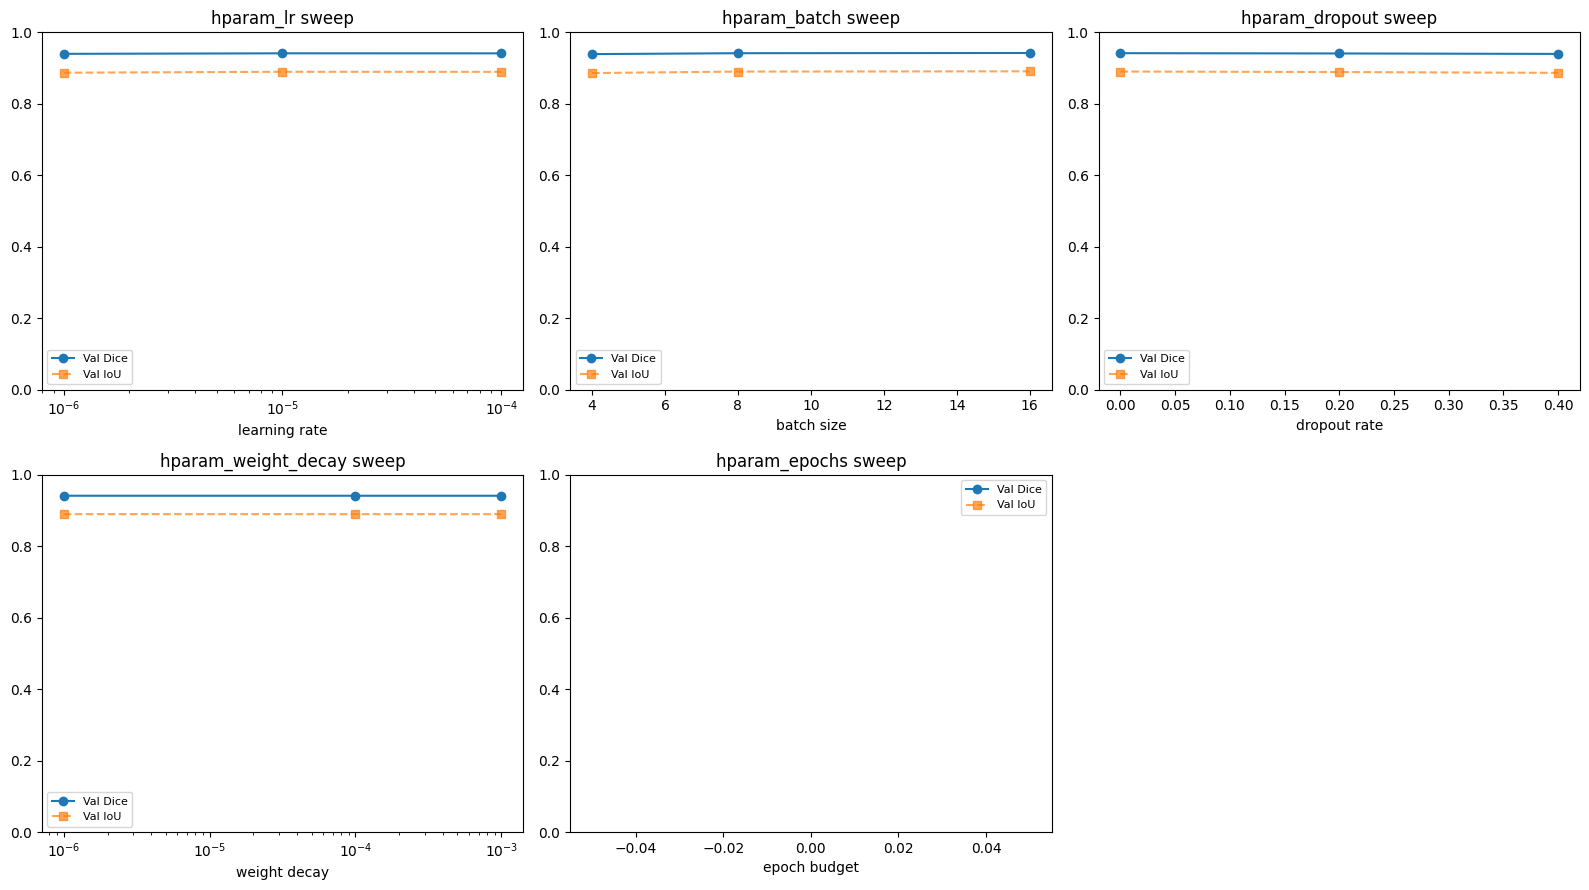

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

def sweep_plot(ax, group, xcol_extract, xlabel, logx=False):
    d = summary_df[summary_df["group"] == group].copy()
    d["x"] = d["model"].apply(xcol_extract)
    d = d.sort_values("x")
    ax.plot(d["x"], d["val_dice"], "o-", label="Val Dice")
    ax.plot(d["x"], d["val_iou"], "s--", label="Val IoU", alpha=0.7)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel); ax.set_ylim(0, 1); ax.legend(fontsize=8)
    ax.set_title(f"{group} sweep")

sweep_plot(axes[0, 0], "hparam_lr", lambda m: float(m.split("_")[-1]), "learning rate", logx=True)
sweep_plot(axes[0, 1], "hparam_batch", lambda m: int(m.split("_")[-1]), "batch size")
sweep_plot(axes[0, 2], "hparam_dropout", lambda m: float(m.split("_")[-1]), "dropout rate")
sweep_plot(axes[1, 0], "hparam_weight_decay", lambda m: float(m.split("_")[-1]) if float(m.split("_")[-1]) > 0 else 1e-6,
           "weight decay", logx=True)
sweep_plot(axes[1, 1], "hparam_epochs", lambda m: int(m.split("_")[-1]), "epoch budget")

axes[1, 2].axis("off")
plt.tight_layout()
plt.savefig(EXP_DIR / "group_hparam_sweeps.png", dpi=150)
plt.show()


/tmp/ipykernel_23/1820749639.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(); plt.grid(alpha=0.3)


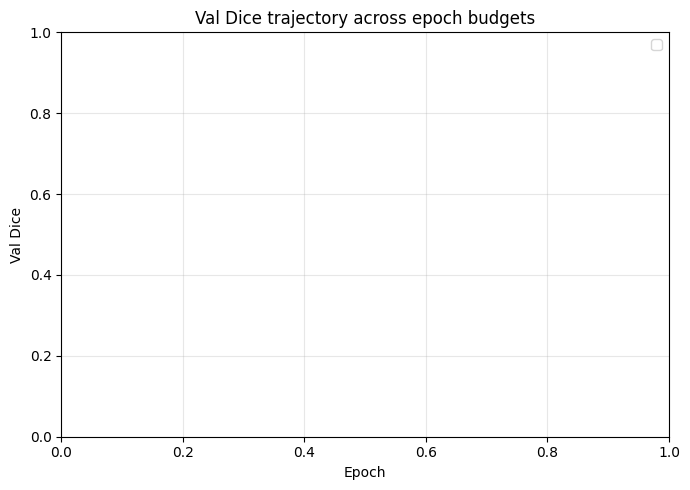

In [26]:
# Dice curves over epochs for the epoch-budget sweep specifically -
# this is the plot to check for "unlearning"/overfitting as epochs grow.
plt.figure(figsize=(7, 5))
for name, hdf in history_frames.items():
    if name.startswith("hp_epochs_") and "val_dice_coef" in hdf.columns:
        plt.plot(hdf["val_dice_coef"].values, label=name)
plt.xlabel("Epoch"); plt.ylabel("Val Dice")
plt.title("Val Dice trajectory across epoch budgets")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EXP_DIR / "epoch_budget_curves.png", dpi=150)
plt.show()


## 25. Done

Stage 1 is complete only when the summary reports **13/13 models**.

The best Stage-1 model is the row with the highest `val_dice` (with `val_iou` reported alongside it). Its checkpoint is saved under:

`/kaggle/working/Segmentation Output/finetuning_experiments/<model>/<model>_best.weights.h5`
